# MS12 — Prédiction ETA · Notebook 01 : Étude des données (CRISP-DM)

**Objectif métier (Business Understanding).** Prédire la **durée réelle** d'un tronçon de trajet de bus
scolaire à Meknès (en minutes), afin d'informer parents et administration de l'heure d'arrivée estimée.

**Démarche.** On suit CRISP-DM : compréhension métier → compréhension des données (ce notebook) →
préparation → modélisation (notebook 02) → évaluation & déploiement (notebook 03).

**Nature des données.** Dataset **semi-réel** : la durée de base de chaque tronçon vient des **vraies routes
OSRM de Meknès** ; les facteurs (trafic, météo, Ramadan, souk, travaux) et les incidents sont simulés à
partir de coefficients de la littérature transport. On vise un **R² honnête (~0.75–0.85)** sur les trajets
normaux — pas un score parfait qui trahirait une fuite de données.

**Étape 0 — Environnement.** On importe les librairies et on se place à la racine du service.

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
# Se placer à la racine du service (ms12-prediction) quel que soit le dossier d'exécution
while os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", palette="deep")
os.makedirs("notebooks/figures", exist_ok=True)
from config import settings
print("Répertoire de travail :", os.getcwd())

Répertoire de travail : C:\Users\Anass\Desktop\SDIA\S9\PFE\transport-scolaire\ms12-prediction


**Étape 1 — Chargement.** On lit le dataset généré par `dataset.py` (une ligne = un tronçon de trajet un jour donné).

In [2]:
import dataset as dataset_mod
if not os.path.exists(settings.dataset_path):
    print("Dataset absent — génération (nécessite OSRM, sinon repli vol d'oiseau)…")
    dataset_mod.generer().to_csv(settings.dataset_path, index=False)
df = pd.read_csv(settings.dataset_path)
print("Dimensions :", df.shape)
df.head()

Dimensions : (4320, 24)


,date,jour_semaine,mois,moment,heure_depart,meteo,trafic,ramadan,jour_souk,travaux_prevus,...,distance_routiere_m,duree_base_s,nb_arrets_restants,nb_montees,nb_descentes,taux_occupation,retard_cumule_s,incident_type,duree_reelle_min,duree_moyenne_historique_s
0,2025-09-08,0,9,matin,7.576,ensoleille,embouteillage,0,0,0,...,1365.1,126.4,3,10,0,0.20,0.0,none,4.623,126.4
1,2025-09-08,0,9,matin,7.626,ensoleille,embouteillage,0,0,0,...,693.6,112.9,2,8,0,0.36,151.0,none,4.129,112.9
2,2025-09-08,0,9,matin,7.676,ensoleille,embouteillage,0,0,0,...,1272.7,176.0,1,5,0,0.46,285.8,none,5.157,176.0
3,2025-09-08,0,9,matin,7.726,ensoleille,embouteillage,0,0,0,...,3104.4,331.3,0,0,0,0.46,419.2,none,10.551,331.3
4,2025-09-08,0,9,matin,7.576,ensoleille,embouteillage,0,0,0,...,1180.7,171.7,3,9,0,0.18,0.0,none,5.877,171.7


**Étape 2 — Qualité des données.** Types, valeurs manquantes et statistiques descriptives.

In [3]:
print("Valeurs manquantes :", int(df.isna().sum().sum()))
print("Jours :", df["date"].nunique(), "| Circuits :", df["circuit_id"].nunique())
df.describe(include="all").T.head(25)

Valeurs manquantes : 0
Jours : 180 | Circuits : 3


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,4320,180,2025-09-08,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
jour_semaine,4320.0,NaN,NaN,NaN,1.972222,1.412138,0.0,1.0,2.0,3.0,4.0
mois,4320.0,NaN,NaN,NaN,6.183333,3.794404,1.0,3.0,5.0,10.0,12.0
moment,4320,2,matin,2160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
heure_depart,4320.0,NaN,NaN,NaN,12.566411,5.028183,6.89,7.5565,12.516,17.578,18.221
meteo,4320,4,ensoleille,2448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trafic,4320,4,dense,1344,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ramadan,4320.0,NaN,NaN,NaN,0.122222,0.32758,0.0,0.0,0.0,0.0,1.0
jour_souk,4320.0,NaN,NaN,NaN,0.205556,0.404154,0.0,0.0,0.0,0.0,1.0
travaux_prevus,4320.0,NaN,NaN,NaN,0.088889,0.284616,0.0,0.0,0.0,0.0,1.0


**Étape 3 — Distribution de la cible.** On regarde `duree_reelle_min`. La distribution est **à queue lourde** :
la grande majorité des trajets sont courts, mais quelques **incidents** (panne, accident…) créent des retards
extrêmes. C'est voulu et réaliste — et ces extrêmes seront des anomalies non prédictibles.

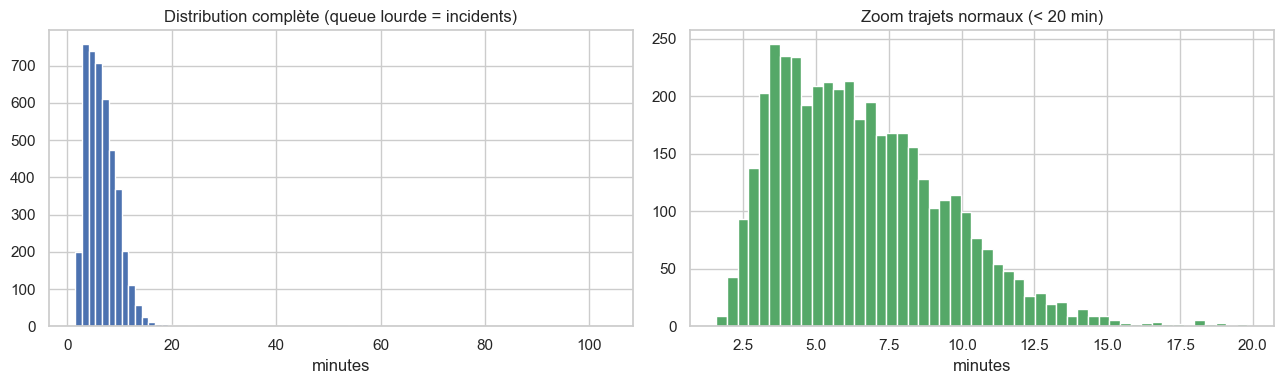

mean      7.081228
50%       6.177000
max     103.269000
Name: duree_reelle_min, dtype: float64


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(df["duree_reelle_min"], bins=80, color="#4c72b0")
ax[0].set_title("Distribution complète (queue lourde = incidents)"); ax[0].set_xlabel("minutes")
zoom = df[df["duree_reelle_min"] < 20]
ax[1].hist(zoom["duree_reelle_min"], bins=50, color="#55a868")
ax[1].set_title("Zoom trajets normaux (< 20 min)"); ax[1].set_xlabel("minutes")
plt.tight_layout(); plt.savefig(f"notebooks/figures/01_distribution_cible.png", dpi=110, bbox_inches="tight"); plt.show()
print(df["duree_reelle_min"].describe()[["mean","50%","max"]])

**Étape 4 — Incidents (label, pas feature).** Fréquence des incidents et leur impact sur la durée.

incident_type
none                 98.77 %
retard_admin          0.32 %
accident               0.3 %
panne                 0.23 %
absence_chauffeur     0.21 %
route_bloquee         0.16 %
Name: proportion, dtype: object


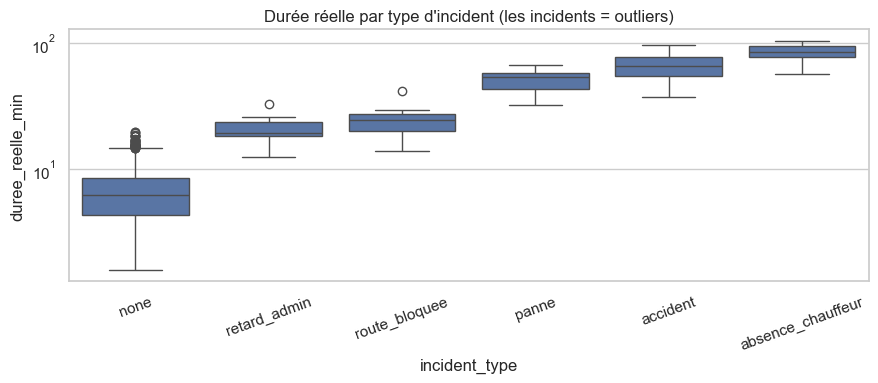

In [5]:
print((df["incident_type"].value_counts(normalize=True) * 100).round(2).astype(str) + " %")
fig, ax = plt.subplots(figsize=(9, 4))
order = df.groupby("incident_type")["duree_reelle_min"].median().sort_values().index
sns.boxplot(data=df, x="incident_type", y="duree_reelle_min", order=order, ax=ax)
ax.set_title("Durée réelle par type d'incident (les incidents = outliers)"); ax.set_yscale("log")
plt.xticks(rotation=20); plt.tight_layout()
plt.savefig(f"notebooks/figures/01_incidents_boxplot.png", dpi=110, bbox_inches="tight"); plt.show()

**Étape 5 — Corrélations.** Relations entre variables numériques et la cible (hors incidents pour la lisibilité).

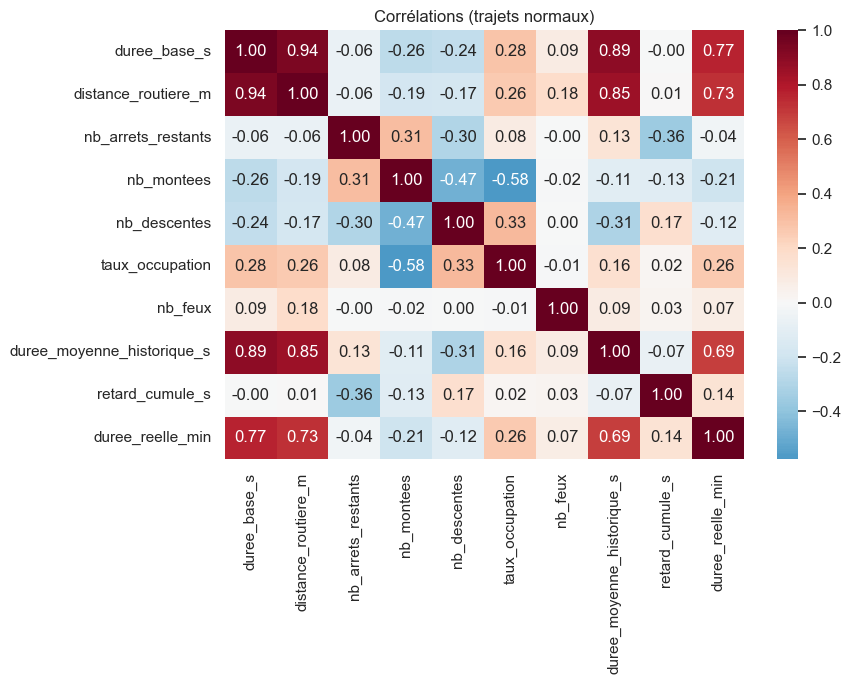

In [6]:
num = ["duree_base_s","distance_routiere_m","nb_arrets_restants","nb_montees","nb_descentes",
       "taux_occupation","nb_feux","duree_moyenne_historique_s","retard_cumule_s","duree_reelle_min"]
corr = df[df["incident_type"]=="none"][num].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Corrélations (trajets normaux)")
plt.tight_layout(); plt.savefig(f"notebooks/figures/01_correlations.png", dpi=110, bbox_inches="tight"); plt.show()

**Étape 6 — Effets contextuels.** Durée moyenne selon le trafic, la météo, le Ramadan et le moment.

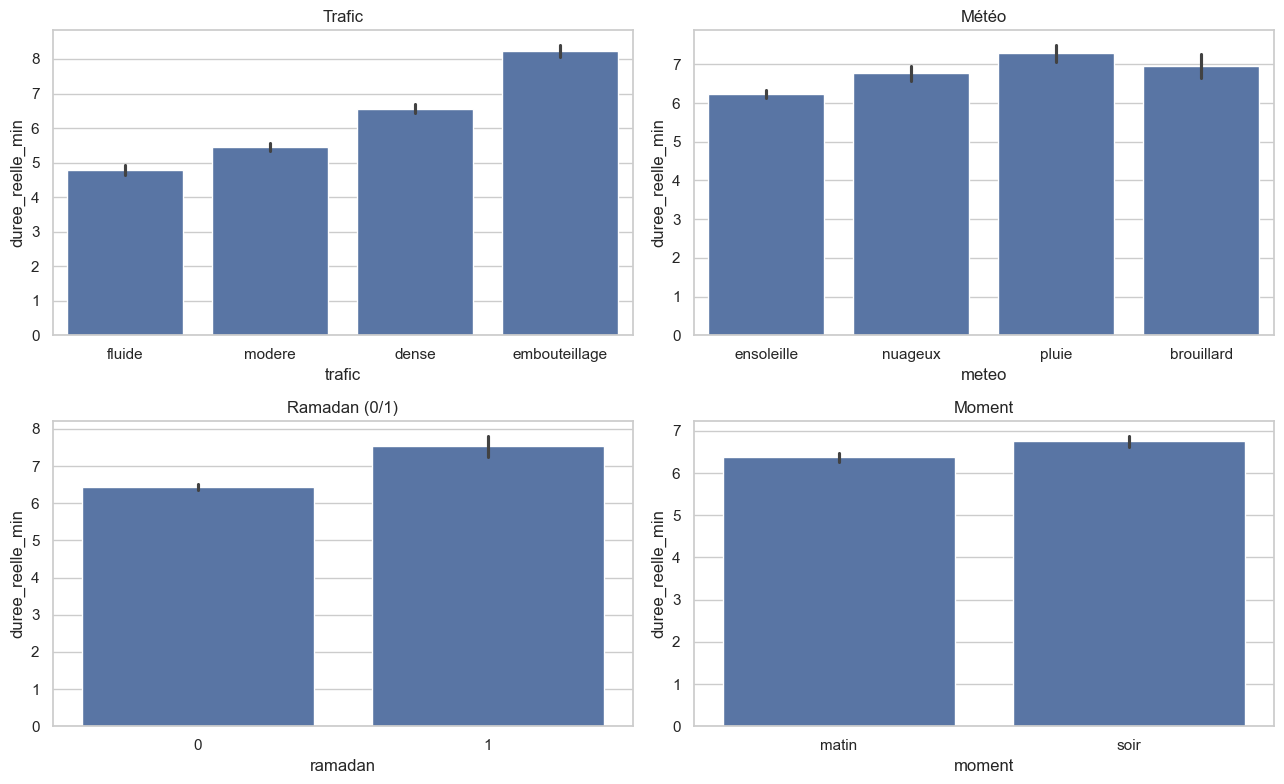

In [7]:
dfn = df[df["incident_type"]=="none"]
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
sns.barplot(data=dfn, x="trafic", y="duree_reelle_min",
            order=["fluide","modere","dense","embouteillage"], ax=ax[0,0]); ax[0,0].set_title("Trafic")
sns.barplot(data=dfn, x="meteo", y="duree_reelle_min",
            order=["ensoleille","nuageux","pluie","brouillard"], ax=ax[0,1]); ax[0,1].set_title("Météo")
sns.barplot(data=dfn, x="ramadan", y="duree_reelle_min", ax=ax[1,0]); ax[1,0].set_title("Ramadan (0/1)")
sns.barplot(data=dfn, x="moment", y="duree_reelle_min", ax=ax[1,1]); ax[1,1].set_title("Moment")
plt.tight_layout(); plt.savefig(f"notebooks/figures/01_effets_contextuels.png", dpi=110, bbox_inches="tight"); plt.show()

**Étape 7 — Préparation (feature engineering).** `features.preparer_features` transforme le brut en matrice
numérique : heure cyclique (sin/cos), one-hot météo/trafic, binaires (Ramadan, souk, travaux, oued),
et numériques. **`incident_type` est exclu** (imprévisible → label, pas feature).

In [8]:
from features import preparer_features, liste_features
X = preparer_features(df)
print("Matrice de features :", X.shape)
print("Colonnes :", list(X.columns))
X.head()

Matrice de features : (4320, 26)
Colonnes : ['distance_routiere_m', 'duree_base_s', 'duree_moyenne_historique_s', 'heure_cos', 'heure_sin', 'is_soir', 'jour_semaine', 'jour_souk', 'meteo_brouillard', 'meteo_ensoleille', 'meteo_nuageux', 'meteo_pluie', 'mois', 'nb_arrets_restants', 'nb_descentes', 'nb_feux', 'nb_montees', 'ramadan', 'retard_cumule_s', 'taux_occupation', 'trafic_dense', 'trafic_embouteillage', 'trafic_fluide', 'trafic_modere', 'travaux_prevus', 'traverse_oued']


,distance_routiere_m,duree_base_s,duree_moyenne_historique_s,heure_cos,heure_sin,is_soir,jour_semaine,jour_souk,meteo_brouillard,meteo_ensoleille,...,nb_montees,ramadan,retard_cumule_s,taux_occupation,trafic_dense,trafic_embouteillage,trafic_fluide,trafic_modere,travaux_prevus,traverse_oued
0,1365.1,126.4,126.4,-0.400989,0.916083,0,0,0,0,1,...,10,0,0.0,0.20,0,1,0,0,0,1
1,693.6,112.9,112.9,-0.412945,0.910756,0,0,0,0,1,...,8,0,151.0,0.36,0,1,0,0,0,1
2,1272.7,176.0,176.0,-0.424832,0.905272,0,0,0,0,1,...,5,0,285.8,0.46,0,1,0,0,0,1
3,3104.4,331.3,331.3,-0.436645,0.899634,0,0,0,0,1,...,0,0,419.2,0.46,0,1,0,0,0,1
4,1180.7,171.7,171.7,-0.400989,0.916083,0,0,0,0,1,...,9,0,0.0,0.18,0,1,0,0,0,0


### Conclusion du notebook 01
- Dataset ancré sur les **vraies distances routières OSRM** de Meknès.
- Cible **à queue lourde** : trajets normaux courts + incidents extrêmes (imprévisibles).
- Signaux clairs : trafic, météo, Ramadan, distance de base, historique.
- Features prêtes → **notebook 02 : comparaison de modèles**.

---

## Enrichissement pour le mémoire — le régime d'entrée du modèle

L'étude ci-dessus décrit les **tronçons** entre deux arrêts, qui sont l'unité d'entraînement du
modèle. Mais depuis que les applications parent et chauffeur demandent l'ETA de la **tournée
restante**, l'entrée du service n'est plus un tronçon : c'est un trajet de 6 à 12 km.

Cet écart de régime est la raison d'être de la garde `facteur_contexte` (étudiée en détail dans
`03_production_strategy`). La figure ci-dessous le rend visible.

> ⚠️ **Ces cellules sont en lecture seule.** Elles chargent `data/ablation/resultats.json`,
> `data/benchmark_summary.json` et `data/eta_dataset.csv` — rien d'autre. Elles n'appellent
> **jamais** `train.main()` : `eta_model.pkl` et `eta_config.json` restent intacts. Les figures
> partent en PDF + PNG 300 dpi dans `notebooks/figures/`, prêtes pour le rapport.


### Deux régimes qui ne se recouvrent pas

En agrégeant le dataset par `(date, moment, circuit_id)`, on reconstruit les trajets entiers à
partir des mêmes lignes — un trajet **est** la concaténation de ses tronçons. On obtient donc une
vérité terrain dans le régime de production sans rien régénérer.

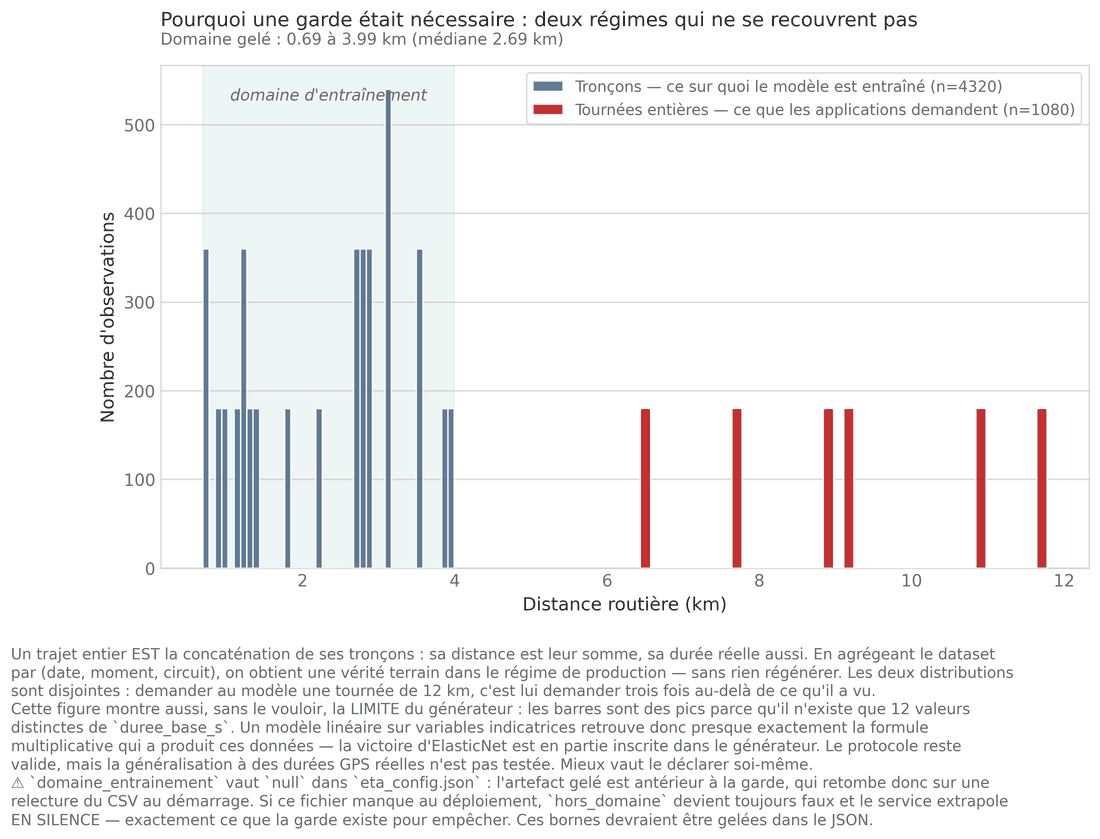

In [ ]:
# Import robuste : certains notebooks font os.chdir(".."), le dossier
# notebooks/ n'est alors plus sur sys.path.
import sys, pathlib
_d = pathlib.Path.cwd()
_d = _d if (_d / "gen_figures_memoire.py").exists() else _d / "notebooks"
sys.path.insert(0, str(_d))
import gen_figures_memoire as gfm
gfm.fig_domaine()